In [1]:
import trenchripper as tr

import warnings
warnings.filterwarnings(action="once")

# addition of active memory manager
import dask
dask.config.set({'distributed.scheduler.active-memory-manager.start': True});
dask.config.set({'distributed.scheduler.worker-ttl': "5m"});
dask.config.set({'distributed.scheduler.allowed-failures': 100});

dask_wd = "/home/lag36/scratch/lag36/dask"

import h5py
import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, widgets

import pandas as pd
import dask.dataframe as dd

/home/lag36/miniconda3/envs/crispri/lib/python3.10/site-packages/pandas/core/computation/expressions.py:21: UserWarning: Pandas requires version '2.8.0' or newer of 'numexpr' (version '2.7.3' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


In [ ]:
HEADPATH = '/home/lag36/scratch/lag36/2024-09-05_lLAG8_EZRDM_Run-01_PipRun-02/'
headpath = HEADPATH

def parse_and_save_futures_results(futures_dict, function_name):
    """
    Parse the results of futures and save them to a DataFrame and a pickle file.
    Args:
        futures_dict (dict): Dictionary with indices as keys and futures as values.
        function_name (str): Name of the function used to generate the futures.
    Returns:
        pd.DataFrame: DataFrame containing the status, done, result, and exception of each future.
    """
    def parse_futures_dict_entry_to_row(future):
        """
        Parse a single future entry to a dictionary row.
        Args:
            future (dask.distributed.Future): Future object to parse.
        Returns:
            dict: Dictionary containing the status, done, result, and exception of the future.
        """
        try:
            result = str(future.result())
        except Exception as e:
            result = str(e)
        future_dict_row = {'status': future.status,
                    'done':future.done(),
                    'result': result,
                    'exception': str(future.exception()),
                    'key': future.key}
        return future_dict_row

    futures_dict_to_table = {index: parse_futures_dict_entry_to_row(future)
                          for index, future in futures_dict.items()}
    
    df_futures = (pd.DataFrame
                  .from_dict(futures_dict_to_table, orient='index')
                  .astype({'status': 'category',
                           'done': bool,
                           'result': 'object',
                           'exception': 'object'})
                  .reset_index()
                  .rename(columns={'index': 'index'})
                  .sort_values(by='index', ascending=True))

    df_futures.to_pickle(f"{headpath}/futures_{function_name}.pkl")

    return df_futures

def deploy_function_in_dask(function, 
                            indices,
                            *args,
                            **kwargs):
    """
    Deploy a function in Dask for each index in the list.
    Args:
        function (callable): Function to deploy.
        indices (list): List of indices to process.
        *args: Additional positional arguments for the function.
        **kwargs: Additional keyword arguments for the function.
    Returns:
        dict: Dictionary with indices as keys and futures as values.
    """
    # futures = []
    futures_dict = {}
    for index in indices:
        future = dask_controller.daskclient.submit(function,
                                               index, # Notice how it is formatted: index is relative to headpath
                                               *args,
                                               **kwargs)
        # futures.append(future)
        futures_dict[index] = future
    # results = dask_controller.daskclient.gather(futures)
    df_futures = parse_and_save_futures_results(futures_dict, function.__name__)
    return df_futures

In [3]:
HEADPATH = '/home/lag36/scratch/lag36/2024-09-05_lLAG8_EZRDM_Run-01_PipRun-02/'
headpath_barcodes = HEADPATH + '/Barcodes/'
headpath_phenotype = HEADPATH + '/Growth_Division/'

# Open kymograph metadata
kymo_metadata_barcodes = (
    dd.read_parquet(
    headpath_barcodes+'/kymograph/metadata',
    engine='pyarrow',
    # Load only these columns: ['File Index', 'File Trench Index', 'trenchid']
    columns=['File Index', 'File Trench Index', 'trenchid', 'fov', 'y (local)', 'x (local)', 'lane orientation', 'row']
    )
    .compute()
    .groupby('trenchid')
    .first()
)

# For phenotypes!
fov_metadata_phenotype = (pd
                .read_hdf(headpath_phenotype + 'metadata.hdf5')
                # .loc[:,60, :]
                .loc[:, ['File Index', 'Image Index']]
                .rename(columns={'File Index': 'File Index Phenotype', 'Image Index': 'Image Index Phenotype'})
                .reset_index()
                )

In [4]:
# Get y values per fov
y_values_trench_rows_all_fovs = \
(kymo_metadata_barcodes
 .loc[:, ['fov', 'y (local)', 'lane orientation', 'row']]
 .groupby(['fov', 'y (local)'])
 .first()
 .reset_index()
)

# Fix missing FOVs Which fov is missing? Manually at the moment
NUMBER_OF_FOVS = 627
missing_fovs = set(range(NUMBER_OF_FOVS)) - set(y_values_trench_rows_all_fovs['fov'].unique())
print(f"Missing fovs: {missing_fovs}")

fov_missing = 578
lane_orientation_missing = y_values_trench_rows_all_fovs.loc[y_values_trench_rows_all_fovs['fov'] == 0, 'lane orientation']
row_missing = y_values_trench_rows_all_fovs.loc[y_values_trench_rows_all_fovs['fov'] == 0, 'row']
y_local_missing = \
(y_values_trench_rows_all_fovs
 .loc[y_values_trench_rows_all_fovs['fov'].isin([577,579])]
 .groupby('row')
 .mean('y (local)')
 ['y (local)']
)

y_values_df_missing = pd.DataFrame({
    'fov': [fov_missing]*len(y_local_missing),
    'y (local)': y_local_missing,
    'lane orientation': lane_orientation_missing.iloc[0],
    'row': row_missing,
})

y_values_trench_rows_all_fovs = \
(
    pd.concat([y_values_trench_rows_all_fovs, y_values_df_missing],
              ignore_index=True)
    .sort_values(by=['fov', 'y (local)'])
)


# FIND EDGES UB 
CHOSEN_BORDER_BUFFER = 20
CHOSEN_TRENCH_LENGTH_BARCODES = 130
IMAGE_HEIGHT = 2960
Y_BUFFER_FEEDING_CHANNEL = -5 # 1 pixel buffer for feeding channel # Negative: cuts more relative to chosen dimensions
MICRONS_PER_PIXEL = 0.2125

y_values_trench_rows_all_fovs = \
(
    y_values_trench_rows_all_fovs
     .assign(y_boundaries_pixels = lambda df_: 
             np.where(df_['lane orientation'] == 'bottom',
             df_['y (local)'] / MICRONS_PER_PIXEL - Y_BUFFER_FEEDING_CHANNEL,
             df_['y (local)'] / MICRONS_PER_PIXEL + CHOSEN_BORDER_BUFFER + CHOSEN_TRENCH_LENGTH_BARCODES + Y_BUFFER_FEEDING_CHANNEL)
     )
)

Missing fovs: {578}


In [5]:
HEADPATH_PHENOTYPE_IMAGES = '/home/lag36/scratch/lag36/2024-09-05_lLAG8_EZRDM_Run-01_PipRun-02/Growth_Division/hdf5/'
# Get all files
import glob
filenames = glob.glob(HEADPATH_PHENOTYPE_IMAGES + 'hdf5_*.hdf5')
# Extract the file index from the filenames
file_indices = sorted([int(filename.split('_')[-1].split('.')[0]) for filename in filenames])

In [ ]:
def clean_feeding_channels_single_hdf5_file(file_index_phenotype, cleaned_channel_name = 'cleaned'):

    with h5py.File(HEADPATH_PHENOTYPE_IMAGES+'hdf5_'+str(file_index_phenotype) +'.hdf5', 'r+') as f:
    
        # Assert that the fov is the same
        assert fov_metadata_phenotype.loc[fov_metadata_phenotype['File Index Phenotype'] == file_index_phenotype, 'fov'].nunique() == 1
        fov = fov_metadata_phenotype.loc[fov_metadata_phenotype['File Index Phenotype'] == file_index_phenotype, 'fov'].iloc[0]

        # Get y boundaries
        y_boundaries = y_values_trench_rows_all_fovs.loc[y_values_trench_rows_all_fovs['fov']==fov, 'y_boundaries_pixels'].astype(int). values
        images = f['mCherry'][:]

        background_pixel_value = int(np.median(images, axis=None))
        images[:, :y_boundaries[0], :] = background_pixel_value  # Set top buffer to 0
        images[:, y_boundaries[1]:y_boundaries[2], :] = background_pixel_value  # Set trench to 0
        images[:, y_boundaries[3]:y_boundaries[4], :] = background_pixel_value  # Set trench to 0
        images[:, y_boundaries[5]:y_boundaries[6], :] = background_pixel_value  # Set bottom buffer to 0
        images[:, y_boundaries[7]:y_boundaries[8], :] = background_pixel_value  # Set bottom buffer to 0
        images[:, y_boundaries[9]:, :] = background_pixel_value  # Set bottom buffer to 0
        
        if cleaned_channel_name in f.keys():
            del f[cleaned_channel_name]
        f[cleaned_channel_name] = images

    return 0

In [7]:
dask_wd = "/home/lag36/scratch/lag36/dask"
dask_controller = tr.trcluster.dask_controller(
    walltime="0:20:00",
    local=False,
    n_workers=500,
    n_workers_min=20,
    memory="4GB",
    working_directory=dask_wd,
)
dask_controller.startdask()
dask_controller.displaydashboard()

10m
0:20:00


In [8]:
df_futures = deploy_function_in_dask(
    clean_feeding_channels_single_hdf5_file, 
    file_indices,
    cleaned_channel_name='cleaned'
)

NameError: name 'headpath' is not defined

In [13]:
def rename_and_delete_channels_from_hdf5_files(
    filepath,
    seg_channel_initial_name = 'cleaned',
    seg_channel_final_name = 'mCherry',
    channels_to_delete = ['cleaned']
):
    """
    Rename the segmentation channel in an HDF5 file and delete specified channels.
    Args:
        headpath (str): Path to the directory containing the HDF5 files.
        filename (str): Name of the HDF5 file to process.
        seg_channel_initial_name (str): Name of the initial segmentation channel to rename.
        seg_channel_final_name (str): New name for the segmentation channel.
        channels_to_delete (list): List of channel names to delete from the HDF5 file.
    Returns:
        int: Returns 0 upon successful completion.
    """
    with h5py.File(filepath,"r+") as infile:
        if seg_channel_final_name in infile.keys():
            del infile[seg_channel_final_name]
        infile[seg_channel_final_name]  = infile[seg_channel_initial_name]

        for seg_channel in channels_to_delete:
            if seg_channel in infile.keys():
                del infile[seg_channel]
    return 0

In [15]:
df_futures = deploy_function_in_dask(
    rename_and_delete_channels_from_hdf5_files, 
    filenames,
    seg_channel_initial_name='cleaned',
    seg_channel_final_name='mCherry',
    channels_to_delete=['cleaned']
)

In [41]:
fov_metadata_phenotype.loc[fov_metadata_phenotype['fov'] == 520]

,fov,timepoints,File Index Phenotype,Image Index Phenotype
31720,520,0,1040,0
31721,520,1,1040,1
31722,520,2,1040,2
31723,520,3,1040,3
31724,520,4,1040,4
...,...,...,...,...
31776,520,56,1041,6
31777,520,57,1041,7
31778,520,58,1041,8
31779,520,59,1041,9


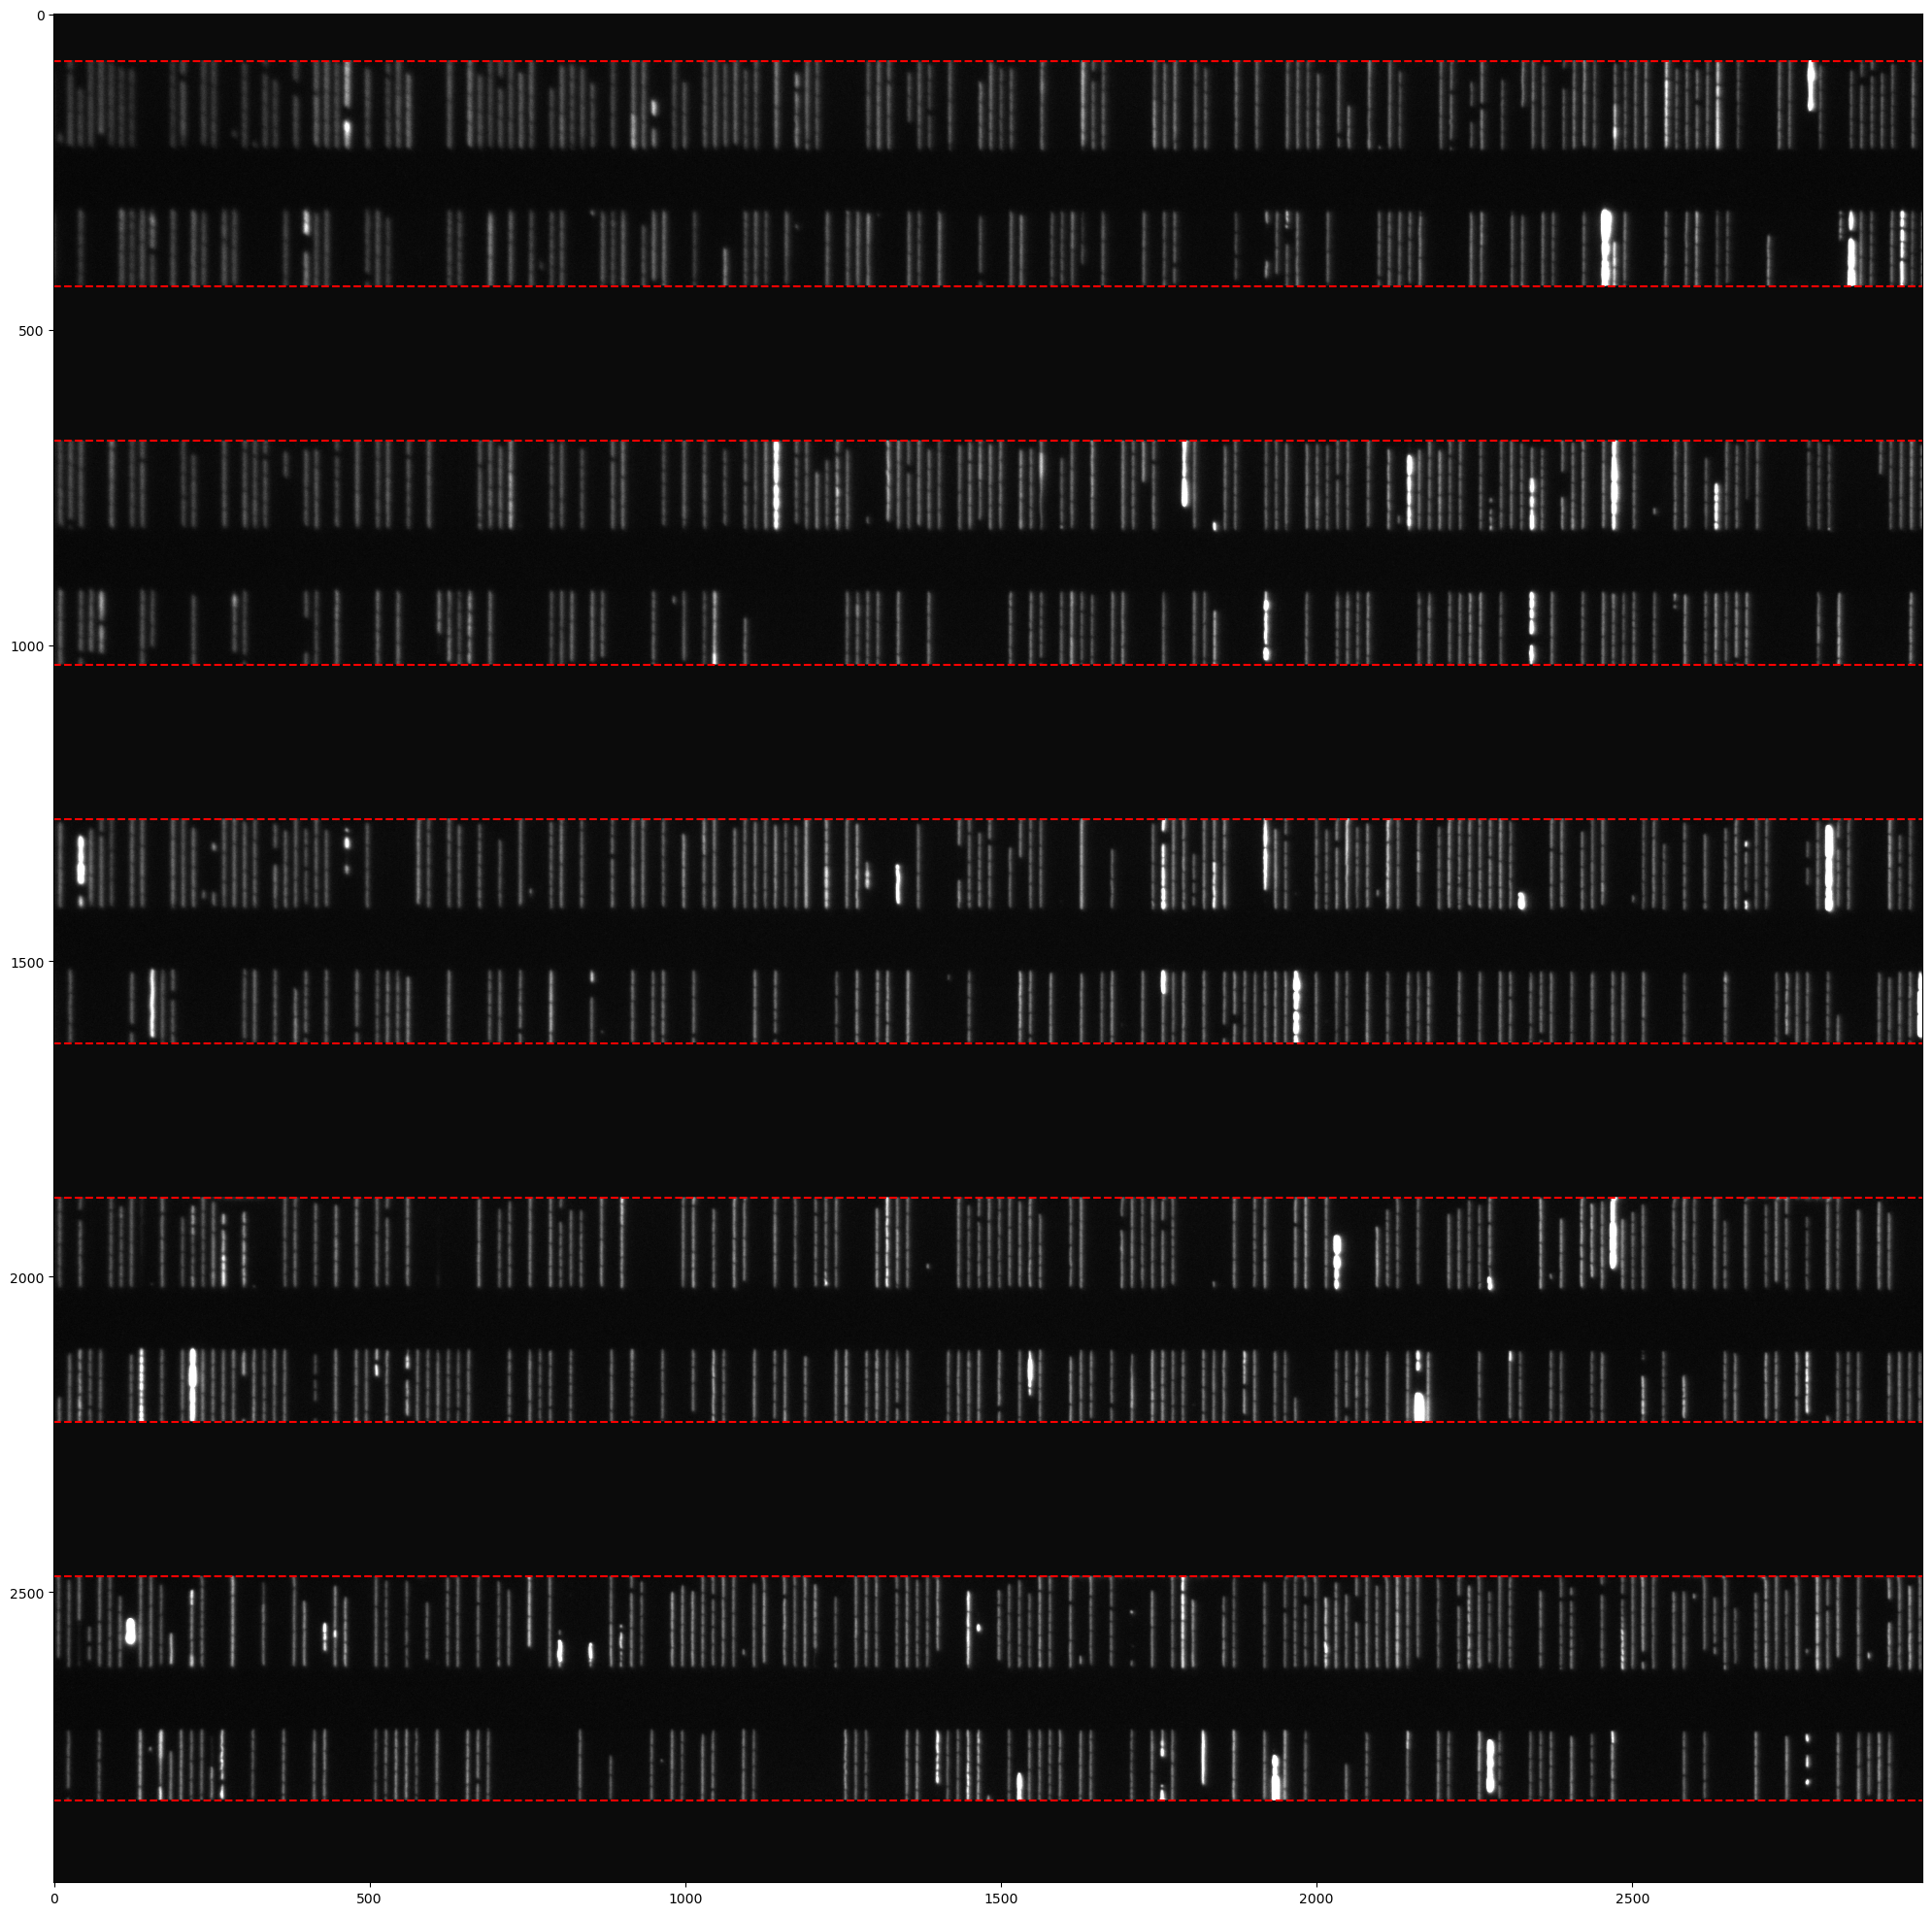

In [42]:
file_index_phenotype = 1040

with h5py.File(HEADPATH_PHENOTYPE_IMAGES+'hdf5_'+str(file_index_phenotype) +'.hdf5', 'r') as f:
    # Assert that the fov is the same
    assert fov_metadata_phenotype.loc[fov_metadata_phenotype['File Index Phenotype'] == file_index_phenotype, 'fov'].nunique() == 1
    fov = fov_metadata_phenotype.loc[fov_metadata_phenotype['File Index Phenotype'] == file_index_phenotype, 'fov'].iloc[0]

    # Get y boundaries
    y_boundaries = y_values_trench_rows_all_fovs.loc[y_values_trench_rows_all_fovs['fov']==fov, 'y_boundaries_pixels'].astype(int). values
    images = f['mCherry'][:]

    plt.figure(figsize=(25, 25))
    plt.imshow(images[0, :, :], cmap='gray', vmin=300, vmax=3000)
    for y in y_boundaries:
        plt.axhline(y=y, color='red', linestyle='--')

In [37]:
y_boundaries

array([  92,  449,  694, 1049, 1294, 1648, 1892, 2248, 2492, 2848])

In [32]:
dask_controller.shutdown()

Done.


2025-07-07 14:48:02,967 - distributed.deploy.adaptive_core - INFO - Adaptive stop
